In [35]:
from src.featurize import featurize
import pandas as pd
from pathlib import Path
import numpy as np

proj_path = Path.cwd().parent 

hydrolases_cleaned = pd.read_csv(proj_path / "data" / "CleanedSequences" / "HydrolasesCleaned.csv")
transferases_cleaned = pd.read_csv(proj_path / "data" / "CleanedSequences" / "TransferasesCleaned.csv")

hydrolases_sample = hydrolases_cleaned.sample(4000,random_state=42)
transferases_sample = transferases_cleaned.sample(4000,random_state=42)

hydrolases_sample = featurize(hydrolases_sample)
hydrolases_sample = np.append(hydrolases_sample,np.array([[3]*4000]).T,axis=1)
transferases_sample = np.append(featurize(transferases_sample),np.array([[2]*4000]).T,axis=1)

samples_array = np.append(hydrolases_sample,transferases_sample,axis=0)

np.random.seed(42)
samples_array_indices= np.random.choice(np.arange(len(samples_array)),size=len(samples_array),replace=False)
train_array = samples_array[samples_array_indices[:6000],:]
test_array = samples_array[samples_array_indices[6000:],:]


In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.model_selection import GridSearchCV


SVC_model = SVC(kernel="rbf",tol=0.01,random_state=42)
SVC_model.fit(train_array[:,:-1],train_array[:,-1])


,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.01
,cache_size,200
,class_weight,None
,verbose,False


In [100]:
from sklearn.ensemble import RandomForestClassifier

RFC_model = RandomForestClassifier(random_state=42)
RFC_model.fit(train_array[:,:-1],train_array[:,-1])

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [101]:
#print(f"SVC model accuracy: {100*SVC_model.score(test_array[:,:-1],test_array[:,-1])}%") 
print(f"Random Forest Accuracy: {100*RFC_model.score(test_array[:,:-1],test_array[:,-1])}%")

Random Forest Accuracy: 100.0%


In [116]:
from itertools import product

features = [amino_acid for amino_acid in "ACDEFGHIKLMNPQRSTVWY"]
features.append("MW")
features.append("Flexibility")
features.append("GRAVY")
features.append("Helix")
features.append("Turn")
features.append("Sheet")
for kmer in ["".join(p) for p in product("ACDEFGHIKLMNPQRSTVWY",repeat=3)]:
    features.append(kmer)
features = np.append(np.array([features]).T,np.array([RFC_model.feature_importances_]).T,axis=1)
features = pd.DataFrame(features)
features = features.rename(columns={0:"Feature",1:"Importance"})


In [117]:

features.sort_values("Importance",ascending=False).head(20)

,Feature,Importance
3307,KFC,9.971257110353519e-05
271,APG,9.955972477267253e-05
6563,THV,9.950847237246758e-05
8023,YYV,9.950209153396385e-05
7279,WDQ,9.950193752383924e-05
148,AHD,9.297184845632946e-05
1437,EMN,9.290571927607905e-05
1602,EWT,8.63482335697575e-05
4911,PFG,8.632174415961508e-05
2950,IHF,8.630877295481439e-05


[]

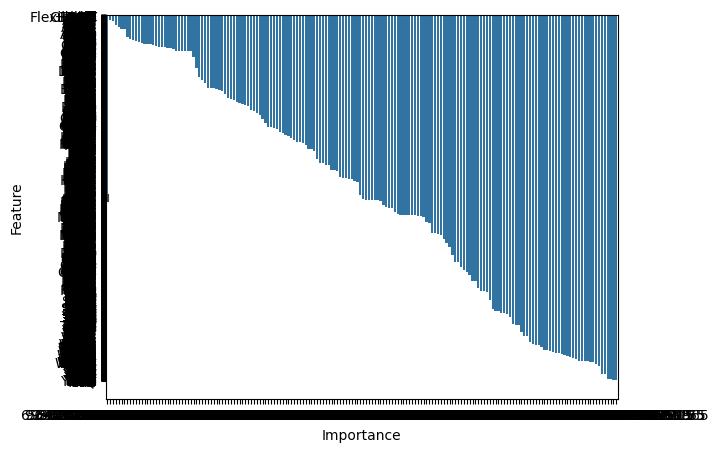

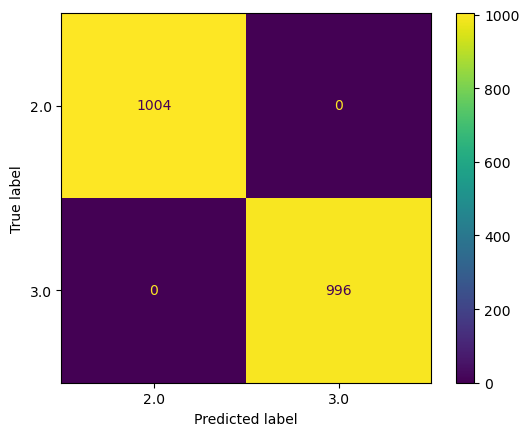

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt
X_test, y_test = test_array[:,:-1],test_array[:,-1]
"""ax = plt.figure(1).add_axes([0.1,0.1,0.8,0.8])"""
ConfusionMatrixDisplay.from_estimator(RFC_model, X_test, y_test)
"""sns.barplot(data=features,x="Importance",y="Feature",ax=ax)
plt.plot()"""